In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pykonal

### Inicializando o "Solver" do pykonal


In [27]:
solver = pykonal.EikonalSolver(coord_sys="cartesian")

# Set the coordinates of the lower bounds of the computational grid.
# For Cartesian coordinates this is x_min, y_min, z_min.
solver.velocity.min_coords = 0, 0, 0 

# Set the interval between nodes of the computational grid (in Kilometers).
# For Cartesian coordinates this is dx, dy, dz.
solver.velocity.node_intervals = 1, 1, 1

# Set the number of nodes in the computational grid.
# For Cartesian coordinates this is nx, ny, nz.
solver.velocity.npts = 30, 30, 1

### Definindo o modelo de velocidade

In [28]:
dg_over = 10 / 100
xover = np.arange(0, 2900 / 1000 + dg_over, dg_over)
zover = np.arange(0, 2900 / 1000 + dg_over, dg_over)

v_line_z = 1.5 + zover
v_line_x = np.tile(0.3 * xover, (len(zover), 1))
v_depth = np.tile(v_line_z[:, np.newaxis], (1, len(xover))) + v_line_x

v_depth = v_depth.reshape(30,30,1) # necessário adicionar a terceira dimensão para o modelo do Solver

In [23]:
len(zover)

30

### Atribuindo o modelo de velocidade ao "Solver"

In [29]:
solver.velocity.values = v_depth

In [ ]:
type(v_depth)

numpy.ndarray

### Definindo a origem da fonte 

In [31]:
# Initialize the source. This is the trickiest part of the example.
src_idx = 10, 0, 0 

# Set the traveltime at the source node to 0.
solver.traveltime.values[src_idx] = 0

# Set the unknown flag for the source node to False.
# This is an FMM state variable indicating which values are completely unknown. 
# Setting it to False indicates that the node has a tentative value
# assigned to it. In this case, the tentative value happens to be the true,
# final value.
solver.unknown[src_idx] = False
# Push the index of the source node onto the narrow-band heap.
solver.trial.push(*src_idx)

1

### Resolve o sistema 

In [32]:
# Solve the system.
solver.solve()

1

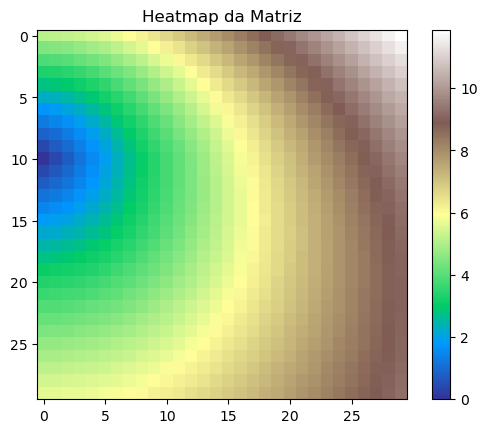

In [33]:
plt.imshow(solver.traveltime.values, cmap='terrain', interpolation='none')
plt.colorbar()  # Exibe a barra de cores para referência
plt.title("Heatmap da Matriz")
plt.show()

### Construindo a função para retornar um df

### Plotando o gráfico  

In [ ]:
def generateDataFrame(nPoints: tuple, nodeIntervals: tuple, velocityModel: np.ndarray, sourceOrigin: tuple) -> pd.DataFrame:
    solver = pykonal.EikonalSolver(coord_sys="cartesian")

    solver.velocity.min_coords = 0, 0, 0 

    solver.velocity.node_intervals = [*nodeIntervals]
    solver.velocity.npts = [*nPoints]
    solver.velocity.values = velocityModel

    solver.traveltime.values[sourceOrigin] = 0
    solver.unknown[sourceOrigin] = False
    solver.trial.push(*sourceOrigin)

    solver.solve()

    travelTimes = np.squeeze(solver.traveltime.values) #Para remover a Terceira dimensão

    dados = [{'x': x, 'z': z, 'travel_time': travelTimes[x][z],'source_x0': sourceOrigin[0],'source_z0': sourceOrigin[1]} 
         for x in range(travelTimes.shape[0]) 
         for z in range(travelTimes.shape[1])]

    df = pd.DataFrame(dados)

    return df

In [43]:
def generateMultipleData(nPoints: tuple, nodeIntervals: tuple, velocityModel: np.ndarray,sourceOriginInterval: np.array) -> pd.DataFrame:
    """
    - sourceOriginInterval: np.array -> Must be the interval of the source in x and z axis, 
    e.g: [[0,0], [2,10]]
    in this case, all the pairs (0,0), (0,1), (0,2)... going trough the 33 pairs 

        - x= [0,1,2], z = [0,1,2,3,4,5,6,7,8,9,10]
    """

    xInterval = np.arange(sourceOriginInterval[0][0], sourceOriginInterval[1][0] + 1)
    zInterval = np.arange(sourceOriginInterval[0][1], sourceOriginInterval[1][1] + 1)

    frames = []
    
    for x in xInterval:
        for z in zInterval:
            frames.append(generateDataFrame(nPoints, nodeIntervals, velocityModel, (x,z,0)))
    
    return pd.concat(frames)



In [44]:
generateMultipleData((30,30,1), (1,1,1), v_depth, [[0,0],[1,2]])

,x,z,travel_time,x0,z0
0,0,0,0.000000,0,0
1,0,1,0.653595,0,0
2,0,2,1.298810,0,0
3,0,3,1.933169,0,0
4,0,4,2.556145,0,0
...,...,...,...,...,...
895,29,25,11.764801,1,2
896,29,26,11.918292,1,2
897,29,27,12.074732,1,2
898,29,28,12.233821,1,2


In [12]:
df = generateDataFrame((181,361,1), (1,1,1), v_depth, (10, 10, 0))
print(df.head(5))
# plt.imshow(a, cmap='terrain', interpolation='none')
# plt.colorbar()  # Exibe a barra de cores para referência
# plt.title("Heatmap da Matriz")
# plt.show()

   x  z  travel_time  x0  y0
0  0  0     9.199007  10  10
1  0  1     8.752003  10  10
2  0  2     8.331889  10  10
3  0  3     7.942345  10  10
4  0  4     7.587205  10  10


In [95]:
import torch
import pandas as pd

# Exemplo: Simulando um DataFrame com a estrutura que você mencionou
Nx, Nz = 181, 361  # Exemplo de dimensões do grid (ajuste conforme necessário)

x_values = torch.arange(Nx).repeat_interleave(Nz)  # x se repete em blocos
z_values = torch.arange(Nz).repeat(Nx)  # z varia rapidamente
t_values = torch.rand(Nx * Nz)  # Simulando valores de t(x, z)

print(x_values)

# Convertendo para DataFrame (como seus dados estão armazenados)
df = pd.DataFrame({'x': x_values.numpy(), 'z': z_values.numpy(), 't': t_values.numpy()})

# Convertendo para tensores 2D no formato correto
t_tensor = t_values.view(Nx, Nz)  # (Nx, Nz)

dx = 1.0  # Supondo espaçamento uniforme em x (ajuste conforme necessário)

# Estimando px usando diferenças finitas centrais
px = (t_tensor[2:, :] - t_tensor[:-2, :]) / (2 * dx)

# Adicionando padding para manter o tamanho original
px = torch.nn.functional.pad(px, (0, 0, 1, 1))  # Preenche as bordas

print(px.shape)  # Deve ser (Nx, Nz), igual ao shape de t(x, z)

tensor([  0,   0,   0,  ..., 180, 180, 180])
torch.Size([181, 361])


In [106]:
import torch


x_out = torch.as_tensor(df['x'].values, dtype=torch.float32)
y_out = torch.as_tensor(df['z'].values, dtype=torch.float32)
t_var = torch.as_tensor(df['travel_time'].values, dtype=torch.float32)


# Convertendo para tensores 2D no formato correto
t_tensor = t_var.view(181,361)  # (Nx, Nz)

dx = 1.0  # Supondo espaçamento uniforme em x (ajuste conforme necessário)

# Estimando px usando diferenças finitas centrais
px = (t_tensor[2:, :] - t_tensor[:-2, :]) / (2 * dx)

# Adicionando padding para manter o tamanho original
px = torch.nn.functional.pad(px, (0, 0, 1, 1))  # Preenche as bordas

print(px)  # Deve ser (Nx, Nz), igual ao shape de t(x, z)


tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-0.4532, -0.4750, -0.4982,  ..., -0.2552, -0.2552, -0.2552],
        [-0.4225, -0.4450, -0.4694,  ..., -0.2529, -0.2529, -0.2529],
        ...,
        [ 0.3004,  0.3006,  0.3007,  ..., -0.0027, -0.0032, -0.0037],
        [ 0.2995,  0.2997,  0.2998,  ..., -0.0019, -0.0024, -0.0029],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]])
